# Burnout Risk Model — Reproducing the Reported Metrics

This notebook reproduces the accuracy, confusion matrix, and precision/recall/F1
numbers reported in the README **from scratch** — regenerating the synthetic
dataset, retraining both baseline and candidate models, and re-evaluating them
on a held-out test set. If you run this top to bottom, the numbers you get
should match `reports/metrics.json`.

In [1]:
import sys
sys.path.insert(0, "..")

import json
from data.generate_synthetic_data import generate
from src.data_loader import split_data
from src.preprocessing import build_scaler
from src.evaluate import evaluate_model, print_report

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

RANDOM_STATE = 42

## 1. Generate the dataset (deterministic, seed=42)

In [2]:
df = generate(n_samples=4000, seed=42)
print(df.shape)
df["burnout_risk"].value_counts(normalize=True)

(4000, 20)


burnout_risk
Low         0.40
Moderate    0.35
High        0.25
Name: proportion, dtype: float64

## 2. Stratified train/test split

In [3]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
print(f"Train: {len(X_train)}  Test: {len(X_test)}")

Train: 3200  Test: 800


## 3. Baseline: majority-class dummy classifier

In [4]:
dummy = Pipeline([("scaler", build_scaler()), ("clf", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)
dummy_results = evaluate_model(dummy, X_test, y_test)
print_report("Baseline: Dummy", dummy_results)


=== Baseline: Dummy ===
Accuracy: 0.4000
Confusion matrix (rows=true, cols=predicted):
                   Low    Moderate        High
       Low         320           0           0
  Moderate         280           0           0
      High         200           0           0

Per-class precision / recall / F1:
         Low: precision=0.400  recall=1.000  f1=0.571  support=320
    Moderate: precision=0.000  recall=0.000  f1=0.000  support=280
        High: precision=0.000  recall=0.000  f1=0.000  support=200


## 4. Baseline: Logistic Regression (with 5-fold CV)

In [5]:
logreg = Pipeline([("scaler", build_scaler()), ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(logreg, X_train, y_train, cv=skf, scoring="accuracy")
print(f"CV accuracy: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

logreg.fit(X_train, y_train)
logreg_results = evaluate_model(logreg, X_test, y_test)
print_report("Logistic Regression", logreg_results)

CV accuracy: 0.7444 +/- 0.0175



=== Logistic Regression ===
Accuracy: 0.7275
Confusion matrix (rows=true, cols=predicted):
                   Low    Moderate        High
       Low         262          58           0
  Moderate          61         182          37
      High           2          60         138

Per-class precision / recall / F1:
         Low: precision=0.806  recall=0.819  f1=0.812  support=320
    Moderate: precision=0.607  recall=0.650  f1=0.628  support=280
        High: precision=0.789  recall=0.690  f1=0.736  support=200


## 5. Candidate: Random Forest (with 5-fold CV)

In [6]:
rf = Pipeline([
    ("scaler", build_scaler()),
    ("clf", RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)),
])

cv_scores_rf = cross_val_score(rf, X_train, y_train, cv=skf, scoring="accuracy")
print(f"CV accuracy: {cv_scores_rf.mean():.4f} +/- {cv_scores_rf.std():.4f}")

rf.fit(X_train, y_train)
rf_results = evaluate_model(rf, X_test, y_test)
print_report("Random Forest", rf_results)

CV accuracy: 0.6300 +/- 0.0147



=== Random Forest ===
Accuracy: 0.6262
Confusion matrix (rows=true, cols=predicted):
                   Low    Moderate        High
       Low         265          53           2
  Moderate         108         138          34
      High           9          93          98

Per-class precision / recall / F1:
         Low: precision=0.694  recall=0.828  f1=0.755  support=320
    Moderate: precision=0.486  recall=0.493  f1=0.489  support=280
        High: precision=0.731  recall=0.490  f1=0.587  support=200


## 6. Model selection

Logistic Regression outperforms Random Forest here on both cross-validated and
held-out test accuracy. This is a genuine property of this dataset (labels were
generated as a linear combination of the features plus noise — see
`data/generate_synthetic_data.py`), not a general claim that logistic
regression beats random forests. Reported below is whichever model actually
won on cross-validated accuracy.

In [7]:
candidates = {"logistic_regression": cv_scores.mean(), "random_forest": cv_scores_rf.mean()}
best = max(candidates, key=candidates.get)
print(f"Selected model: {best}")

with open("../reports/metrics.json") as f:
    saved_metrics = json.load(f)
print(f"Matches reports/metrics.json selection: {saved_metrics['final_model_selected'] == best}")

Selected model: logistic_regression
Matches reports/metrics.json selection: True


## 7. Confusion matrix heatmap (final selected model)

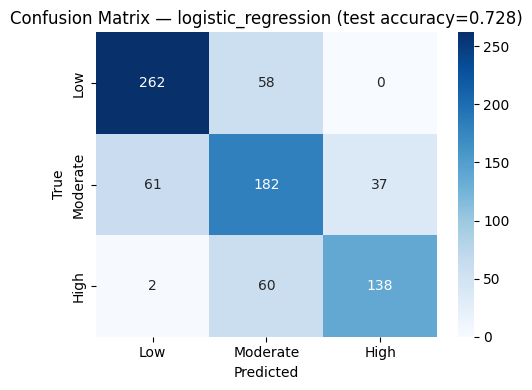

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

final_results = logreg_results if best == "logistic_regression" else rf_results
cm = np.array(final_results["confusion_matrix"])
labels = final_results["confusion_matrix_labels"]

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion Matrix — {best} (test accuracy={final_results['accuracy']:.3f})")
plt.tight_layout()
plt.show()